# Structural diversity indices from the RH profile

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/huizhml/global-vegetation-structure/blob/master/notebooks/02_structure_metrics.ipynb)

In [Get the data](01_get_the_data.ipynb) we read all 101 RH metrics for an area into a data cube. Here, we use the RH profile of each pixel to calculate and map structural diversity indices.

We first compare two forest stands with similar canopy height but different RH profiles. We then calculate canopy ratio, foliage height diversity and the effective number of layers for the whole area.

Finally, we save canopy height and the three indices as a four-band GeoTIFF.

In [1]:
%pip install -q rioxarray

The following cell loads the tile index and defines open_tile and open_cube, using the same code as [Get the data](01_get_the_data.ipynb).

In [2]:
import os
from concurrent.futures import ThreadPoolExecutor

import fsspec
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray
import xarray as xr
from pyproj import Transformer
from rasterio.errors import RasterioIOError
from rioxarray.merge import merge_arrays
from shapely.geometry import box

# Reading over HTTP: skip directory listings, merge neighbouring byte ranges.
os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"
os.environ["GDAL_HTTP_MERGE_CONSECUTIVE_RANGES"] = "YES"

STORE = "https://data.source.coop/geoai-ucph/gvsm"
YEAR = 2020
RHS = list(range(101))  # RH0 ... RH100

# The dataset's index: one row per Sentinel-2 tile with the tile's footprint.
INDEX = gpd.read_parquet(f"{STORE}/gvsm_{YEAR}.parquet", columns=["id", "geometry"], filesystem=fsspec.filesystem("https"))
INDEX["tile"] = INDEX.id.str[:5]  # the id is <tile>_<year>


def tile_url(tile, rh, year=YEAR):
    """10 m file: one per Sentinel-2 (MGRS) tile and RH metric. Q1 = the median prediction."""
    return f"{STORE}/{year}/{tile}/RH{rh}_Q1.tif"


def tiles_covering(west, south, east, north):
    """Tiles that a lon/lat box touches: a single tile if one holds the whole box."""
    area = box(west, south, east, north)
    holding = INDEX.tile[INDEX.covers(area)]
    return [holding.iloc[0]] if len(holding) else sorted(INDEX.tile[INDEX.intersects(area)])


def open_tile(tile, rhs=RHS, year=YEAR):
    """One tile as a lazy (rh, y, x) cube of heights in metres. None if the tile does not exist."""

    def open_metric(rh):
        metric = rioxarray.open_rasterio(tile_url(tile, rh, year), chunks=1024, masked=True, lock=False)
        return metric.squeeze("band", drop=True)

    try:
        with ThreadPoolExecutor(16) as pool:  # the 101 headers are fetched in parallel
            metrics = list(pool.map(open_metric, rhs))
    except RasterioIOError:
        return None
    cube = (xr.concat(metrics, dim=pd.Index(list(rhs), name="rh")) / 10).rename("height")  # decimetres -> metres
    cube.attrs = {"units": "m", "tile": tile, "year": year}
    return cube


def open_cube(west, south, east, north, rhs=RHS, year=YEAR):
    """Lazy (rh, y, x) cube for a lon/lat box, in the UTM zone of its first tile."""
    tiles = [open_tile(t, rhs, year) for t in tiles_covering(west, south, east, north)]
    parts = [t.rio.clip_box(west, south, east, north, crs="EPSG:4326") for t in tiles if t is not None]
    if not parts:
        raise ValueError("no tile found for this box")
    if len(parts) == 1:
        return parts[0]
    # Several tiles: bring them to one UTM zone and mosaic (this loads the data).
    crs = parts[0].rio.crs
    parts = [p if p.rio.crs == crs else p.rio.reproject(crs, resolution=10) for p in parts]
    return merge_arrays(parts)

In [3]:
# Plotting functions for the figures below. The data steps are in the sections; these only draw.


def plot_stands(stand_rh, stand_profiles):
    """The stands side by side: RH profile and vertical profile, as mean (line) ± 1 std (band) over the pixels of a stand."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
    band = dict(color="grey", alpha=0.25, lw=0)
    for (name, rh), ls in zip(stand_rh.items(), ["-", "--", ":", "-."]):
        mean, std = rh.mean("pixel"), rh.std("pixel")
        axes[0].plot(rh.rh, mean, color="black", ls=ls, lw=2, label=f"stand {name}")
        axes[0].fill_between(rh.rh, mean - std, mean + std, **band)
        profile = stand_profiles[name]
        mean, std = profile.mean("pixel"), profile.std("pixel")
        axes[1].plot(mean, profile.height, color="black", ls=ls, lw=2, label=f"stand {name}")
        axes[1].fill_betweenx(profile.height, mean - std, mean + std, **band)
    bin_size = float(profile.height[1] - profile.height[0])
    axes[0].set(xlabel="RH n (% of returned energy)", ylabel="height (m)", title="RH profile, mean ± 1 std")
    axes[1].set(xlabel=f"returned energy per {bin_size:.1f} m (%)", title="Vertical profile, mean ± 1 std", xlim=(0, None))
    for ax in axes:
        ax.axhline(0, color="grey", lw=0.8)
    axes[0].legend(frameon=False)
    plt.tight_layout()
    plt.show()


DIVERSITY_STYLE = {  # title, colour map, colour range
    "canopy_height": ("Canopy height, RH98 (m)", "inferno", (0, 50)),
    "canopy_ratio": ("Canopy ratio", "RdBu", (0.48, 1)),
    "fhd": ("Foliage height diversity", "viridis", (0, 2)),
    "enl2d": ("Effective number of layers (2D ENL)", "viridis", (1, 7)),
}


def mark_stands(ax, stands_xy):
    """An open circle and a letter for every stand."""
    for (name, (x, y)), offset in zip(stands_xy.items(), [(-14, 6), (6, 6)] * len(stands_xy)):
        ax.plot(x, y, "o", mfc="none", mec="black", mew=1.5, ms=10)
        ax.annotate(name, (x, y), xytext=offset, textcoords="offset points", fontweight="bold", bbox=dict(fc="white", ec="none", pad=1))


def plot_diversity_maps(diversity, stands_xy):
    """Maps of canopy height and of every structural diversity index, with the stands marked."""
    fig, axes = plt.subplots(1, len(diversity.data_vars), figsize=(5 * len(diversity.data_vars), 4.3))
    for ax, name in zip(axes, diversity.data_vars):
        title, cmap, (vmin, vmax) = DIVERSITY_STYLE[name]
        diversity[name].plot.imshow(ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, extend="neither", cbar_kwargs={"label": "", "shrink": 0.8})
        mark_stands(ax, stands_xy)
        ax.set_title(title)
        ax.set_aspect("equal")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 1. Two stands with similar canopy top height

We use the same forest area in Spessart, Germany, as in [Get the data](01_get_the_data.ipynb), reading all 101 RH metrics for an area of approximately 3 × 3 km. Within it, we select two stands, A and B, about 600 m apart along a west–east line. Each stand covers a 100 × 100 m area containing 10 × 10 pixels. The table below shows the mean RH25, RH50, RH75 and RH98 for each stand.

In [4]:
lon, lat = 9.312, 49.937
cube = open_cube(lon - 0.021, lat - 0.0135, lon + 0.021, lat + 0.0135).compute()

STANDS = {"A": (9.3080, 49.937), "B": (9.3164, 49.937)}  # lon, lat
to_utm = Transformer.from_crs("EPSG:4326", cube.rio.crs, always_xy=True)
stands_xy = {name: to_utm.transform(*lonlat) for name, lonlat in STANDS.items()}


def stand_box(data, x, y, half=50):
    """The pixels of `data` in a square of 2 x `half` metres around (x, y). y runs north to south."""
    return data.sel(x=slice(x - half, x + half), y=slice(y + half, y - half))


stand_rh = {name: stand_box(cube, x, y).stack(pixel=("y", "x")) for name, (x, y) in stands_xy.items()}  # (rh, pixel)
pd.DataFrame({f"stand {name}": rh.mean("pixel").sel(rh=[25, 50, 75, 98]).values for name, rh in stand_rh.items()}, index=["RH25", "RH50", "RH75", "RH98"]).astype(float).round(1).T

,RH25,RH50,RH75,RH98
stand A,1.2,5.4,12.9,23.2
stand B,8.5,15.0,18.8,23.2


Both stands have the same mean RH98, but differ in other RHs.

To see how the energy is distributed with height, we convert each pixel's RH profile into a vertical profile using vertical_profile, as in [Get the data](01_get_the_data.ipynb). We then plot the mean RH profile and mean vertical profile for each stand. Shaded bands show ±1 standard deviation across the 100 pixels.

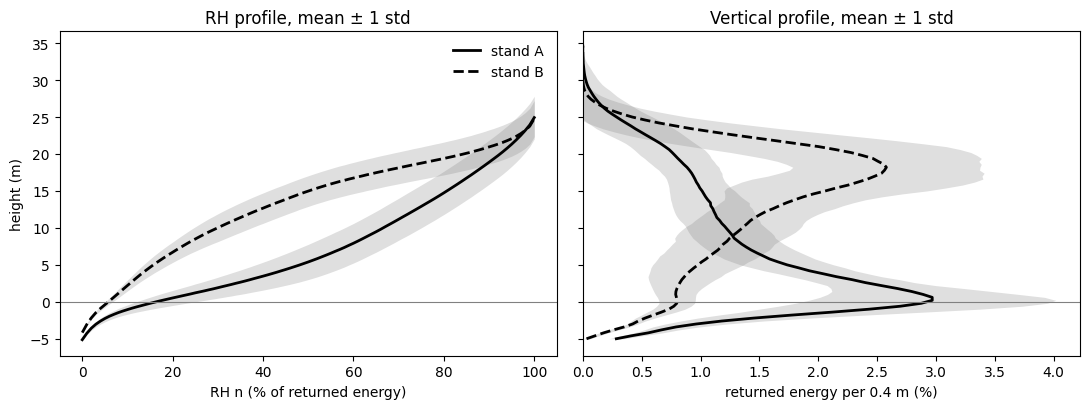

In [5]:
def vertical_profile(rh_heights, bin_size=0.4, bottom=-10, top=50):
    """From one RH profile (RH0 ... RH100, m) to its vertical profile: share of returned energy (%) per height bin.

    RH n is the height by which n % of the returned energy has accumulated, so the RH profile is a cumulative curve.
    Reading that curve at the bin edges and taking differences gives the share in each bin; a 5-bin
    moving average smooths it. The below-ground tail is kept.
    """
    edges = np.arange(bottom, top + bin_size / 2, bin_size)
    cumulative = np.interp(edges, np.maximum.accumulate(rh_heights), RHS)  # RH n never decreases with n
    share = np.convolve(np.diff(cumulative), np.ones(5) / 5, mode="same")
    return xr.DataArray(share, coords={"height": edges[:-1] + bin_size / 2}, dims="height", name="vertical_profile", attrs={"units": "%"})


def pixel_profiles(rh):
    """The vertical profile of every pixel of a stand: (pixel, height)."""
    return xr.concat([vertical_profile(rh.isel(pixel=i).values) for i in range(rh.sizes["pixel"])], dim="pixel")


stand_profiles = {name: pixel_profiles(rh).sel(height=slice(-5, 35)) for name, rh in stand_rh.items()}
plot_stands(stand_rh, stand_profiles)

## 2. Map structural diversity indices

Structural diversity indices summarise different aspects of a pixel's RH profile. Here, we calculate the three indices used in the paper and compare them with canopy height:

| index | definition | reads as |
|---|---|---|
| canopy height | RH98 | Approximate height of the canopy top (m) |
| canopy ratio | (RH98 − RH25) / RH98, with RH25 not below 0 | Vertical distance between RH25 and RH98, relative to canopy height. Values close to 1 indicate that most canopy materials are near the ground. |
| foliage height diversity (FHD) | Shannon entropy −Σ pᵢ ln pᵢ of the vertical profile in 5 m bins, where pᵢ is the share of the non-negative RH metrics that fall in bin i | Diversity of the vertical distribution: higher values indicate that returned energy is spread across more height bins and/or more evenly among them. |
| effective number of layers (2D ENL) | inverse Simpson index 1 / Σ pᵢ² of the same bin shares pᵢ | The number of equally filled 5 m layers that would give the same Σ pᵢ². Compared with FHD it gives more weight to the bins that hold most of the energy. |

In [6]:
def structural_diversity_indices(cube, bin_size=5, top=150):
    """From the RH profile cube (rh, y, x) to a Dataset (y, x) of canopy height and three structural diversity indices."""
    h = cube.values
    rh25, rh98 = np.maximum(h[25], 0), h[98]
    with np.errstate(invalid="ignore", divide="ignore"):
        canopy_ratio = np.where(rh98 > 0, (rh98 - rh25) / rh98, np.nan)

    # Vertical profile in `bin_size` m bins: the number of RH metrics at or above the ground in each bin.
    bins = np.minimum(np.floor(h / bin_size), top // bin_size - 1)
    counts = np.stack([((bins == b) & (h >= 0)).sum(axis=0) for b in range(top // bin_size)]).astype("float32")
    total = counts.sum(axis=0)
    p = counts / np.maximum(total, 1)
    fhd = -(p * np.log(np.where(p > 0, p, 1))).sum(axis=0)

    enl2d = 1 / np.maximum((p**2).sum(axis=0), 1e-6)  # inverse Simpson index; pixels with no bin filled are masked below
    indices = {"canopy_height": rh98, "canopy_ratio": canopy_ratio, "fhd": fhd, "enl2d": enl2d}
    nodata = np.isnan(h).any(axis=0) | (total == 0)
    indices = {name: (("y", "x"), np.where(nodata, np.nan, values).astype("float32")) for name, values in indices.items()}
    return xr.Dataset(indices, coords={"y": cube.y, "x": cube.x}).rio.write_crs(cube.rio.crs)


diversity = structural_diversity_indices(cube)
stand_diversity = pd.DataFrame({name: stand_box(diversity, x, y).mean().to_pandas() for name, (x, y) in stands_xy.items()}).T
stand_diversity.astype(float).round(2)

,canopy_height,canopy_ratio,fhd,enl2d
A,23.18,0.95,1.51,4.04
B,23.19,0.63,1.52,4.15


The table shows the mean of each metric across the 100 pixels in each stand. Stands A and B have similar canopy height, FHD and ENL, but differ in canopy ratio. This reflects the difference in RH25 seen above: FHD and ENL describe the diversity of the vertical distribution, while canopy ratio captures the relative distance between RH25 and RH98.

We now map all four metrics across the study area, with stands A and B marked for reference.

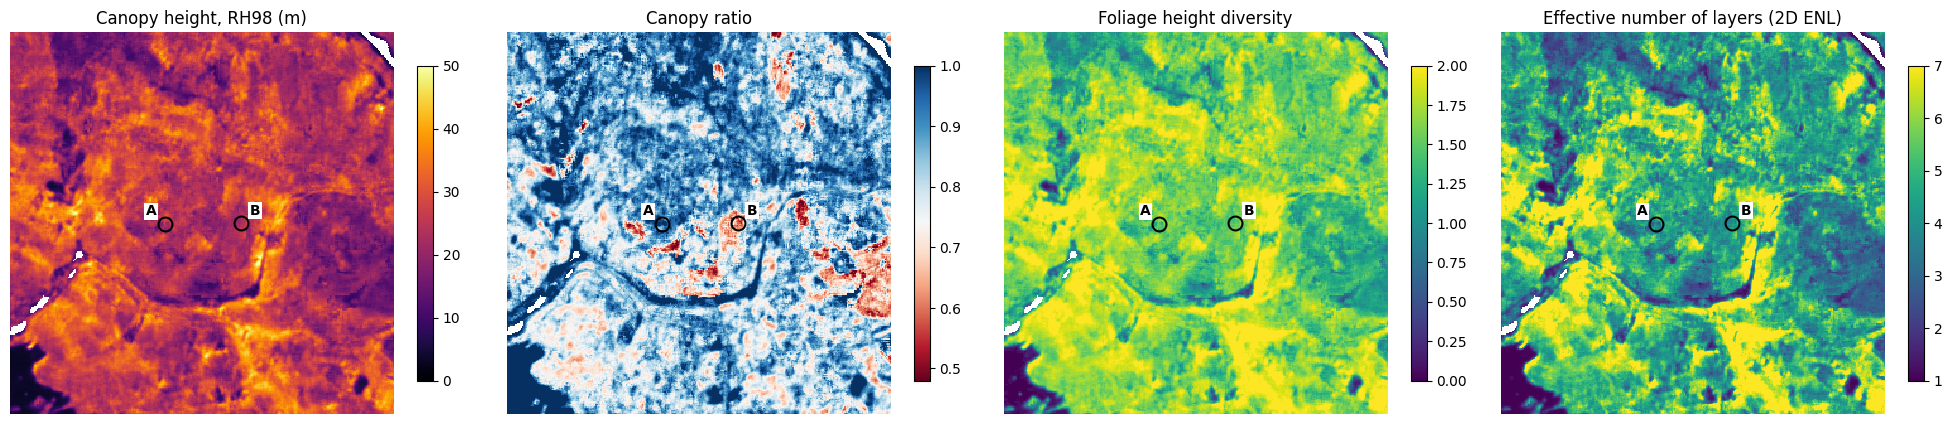

In [7]:
plot_diversity_maps(diversity, stands_xy)

Save the results. Export canopy height and the three structural diversity indices as a four-band GeoTIFF, retaining the cube's 10 m pixel grid.

In [8]:
diversity.rio.to_raster("vsm_structural_diversity.tif")
rioxarray.open_rasterio("vsm_structural_diversity.tif")

<xarray.DataArray (band: 4, y: 303, x: 304)> Size: 1MB
[368448 values with dtype=float32]
Coordinates:
  * band         (band) int64 32B 1 2 3 4
  * y            (y) float64 2kB 5.533e+06 5.533e+06 ... 5.53e+06 5.53e+06
  * x            (x) float64 2kB 5.209e+05 5.209e+05 ... 5.239e+05 5.239e+05
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      ('canopy_height', 'canopy_ratio', 'fhd', 'enl2d')

## More

- [Map structure classes interactively](03_interactive_structure_map.ipynb) (in preparation): select an area, label a few example pixels and use their RH profiles to classify vegetation structure across the area.
- Licence: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Please cite: Zhang, H., Lang, N., Mazurczyk, M., Oehmcke, S., Huang, K., Brandt, M., Fensholt, R., Kariryaa, A., & Igel, C. (2026). A vertical vegetation structure model of the Earth. *EarthArXiv preprint*. [doi:10.31223/X5M22F](https://doi.org/10.31223/X5M22F)